Generated airfoil parameters: 
Maximum camber=  0.52%
Position of maximum camber=  39.37%chord
Maximum thickness =  10.86% chord


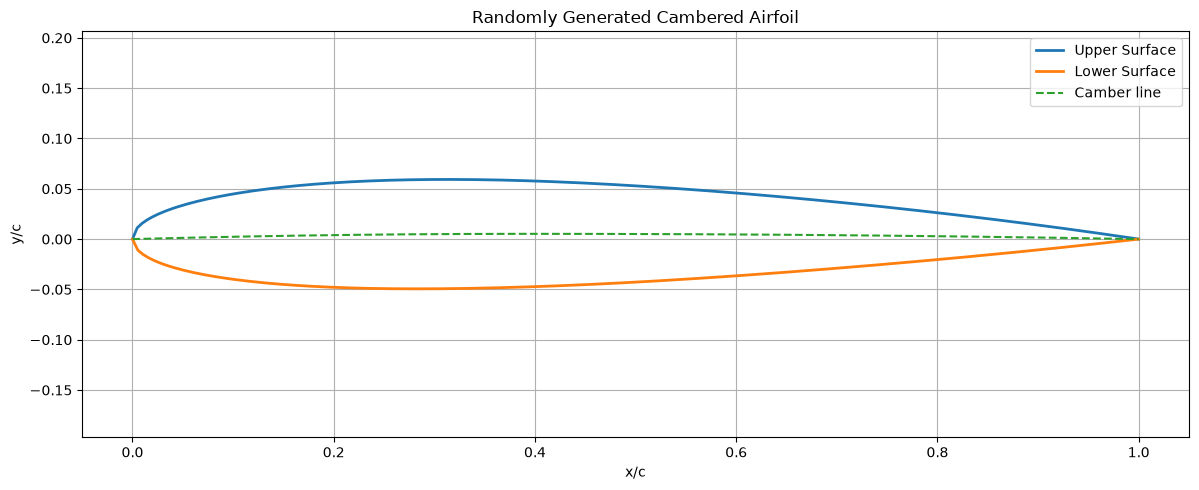

C:\Users\abhis\AppData\Local\Temp\ipykernel_23984\1557703569.py:99: DeprecationWarning: `lagrange` is deprecated and will be removed in SciPy 1.20.0. Use `scipy.interpolate.BarycentricInterpolator` instead.
  poly_upper = scipy_lagrange(xud, yud)
C:\Users\abhis\AppData\Local\Temp\ipykernel_23984\1557703569.py:100: DeprecationWarning: `lagrange` is deprecated and will be removed in SciPy 1.20.0. Use `scipy.interpolate.BarycentricInterpolator` instead.
  poly_lower = scipy_lagrange(xld, yld)



Verification against SciPy:
Upper surface maximum difference: 3.995011462206309e-12
Lower surface maximum difference: 6.829993634382233e-11

Reconstruction errors:
Maximum absolute error: 7.06146400e-03
RMS error: 1.04611110e-03


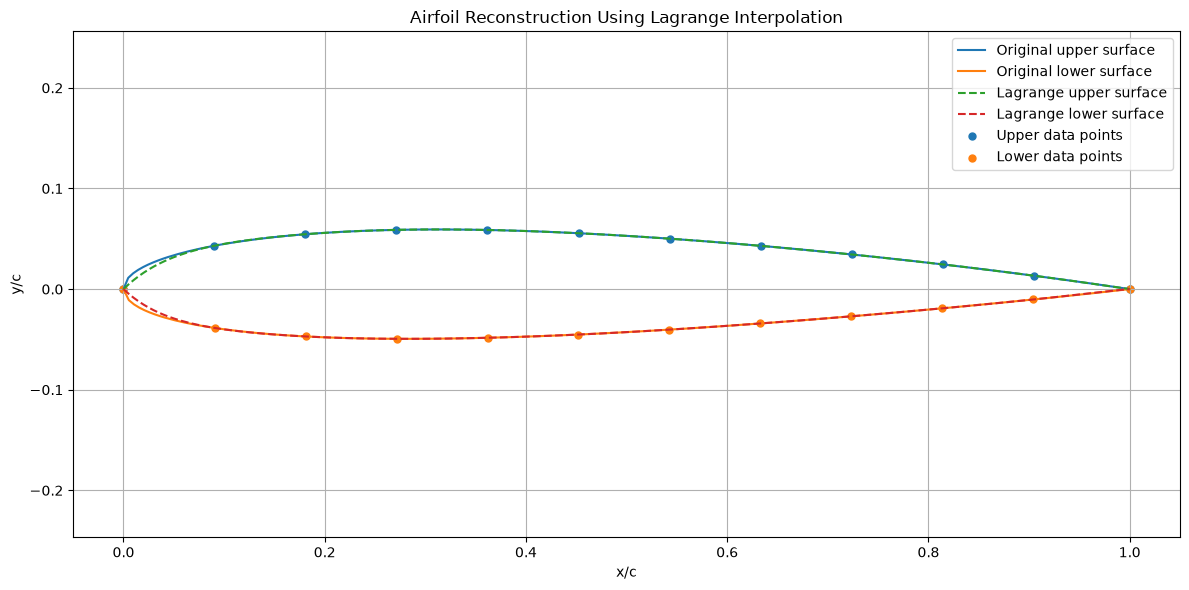


Original points: 200
Selected interpolation points: 12
Selected indices: [  0  18  36  54  72  90 108 126 144 162 180 199]

Verification of Lagrange function against SciPy
Upper x max difference: 8.912720659282058e-07
Upper y max difference: 2.6288612160947917e-08
Lower x max difference: 3.037021087948233e-07
Lower y max difference: 2.9087564372224922e-08

Cubic Spline Reconstruction Errors:
Maximum absolute error: 2.60549213e-03
RMS error:              1.46069861e-04


C:\Users\abhis\AppData\Local\Temp\ipykernel_23984\1557703569.py:235: DeprecationWarning: `lagrange` is deprecated and will be removed in SciPy 1.20.0. Use `scipy.interpolate.BarycentricInterpolator` instead.
  np.max(np.abs(xu_lag - scipy_lagrange(u_data, xu_data)(uu))))
C:\Users\abhis\AppData\Local\Temp\ipykernel_23984\1557703569.py:237: DeprecationWarning: `lagrange` is deprecated and will be removed in SciPy 1.20.0. Use `scipy.interpolate.BarycentricInterpolator` instead.
  np.max(np.abs(yu_lag - scipy_lagrange(u_data, yu_data)(uu))))
C:\Users\abhis\AppData\Local\Temp\ipykernel_23984\1557703569.py:239: DeprecationWarning: `lagrange` is deprecated and will be removed in SciPy 1.20.0. Use `scipy.interpolate.BarycentricInterpolator` instead.
  np.max(np.abs(xl_lag - scipy_lagrange(u_data, xl_data)(uu))))
C:\Users\abhis\AppData\Local\Temp\ipykernel_23984\1557703569.py:241: DeprecationWarning: `lagrange` is deprecated and will be removed in SciPy 1.20.0. Use `scipy.interpolate.Barycentri

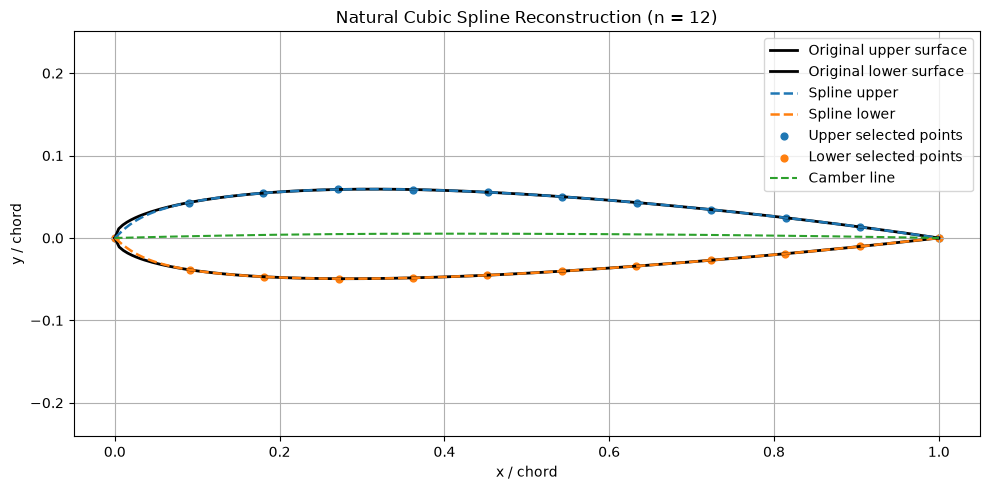

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import lagrange as scipy_lagrange

rng=np.random.default_rng()  #This will help me to pick a number for generating random number within the specified range for the airfoil parameters

#The numbers will be picked up from the below range
m_rng= (0.00, 0.06)
p_rng= (0.20, 0.60)
t_rng= (0.06, 0.18)

m=rng.uniform(*m_rng)
p=rng.uniform(*p_rng)
t=rng.uniform(*t_rng)

print("Generated airfoil parameters: ")
print(f"Maximum camber= {100*m: .2f}%")
print(f"Position of maximum camber= {100*p: .2f}%chord")
print(f"Maximum thickness = {100*t: .2f}% chord")

# Now let's define chord length and number of points (As discussed in the class we'll not have any input function, hence we'll used a number beforehand)

c=1.0 # we'll define the range of chord from 0 to 1 because whatever parameters that we take are with respect to chord, i.e in percentage of chord
N=200

x=np.linspace(0,c,N) #creates equally spaced points within the chord range
xc= x/c              # Normalising the coordinates with respect to the chord

yc=np.zeros(N)
dyc_dx=np.zeros(N)

for i in range(N):
  if xc[i]<p:
    yc[i] = (m/p**2)*(2*p*xc[i]-xc[i]**2)
    dyc_dx[i] = (2*m/p**2)*(p-xc[i])

  else:
    yc[i] = (m/(1-p)**2) * ((1-2*p) + 2*p*xc[i] - xc[i]**2)
    dyc_dx[i] = (2*m/(1-p)**2) * (p-xc[i])

yt=5*t*(0.2969*np.sqrt(xc)-0.1260*xc-0.3516*xc**2+0.2843*xc**3-0.1036*xc**4) #formula taken from Wikipedia

theta=np.arctan(dyc_dx)

xu = x - yt*np.sin(theta)*c
yu = yc*c + yt*np.cos(theta)*c

xl= x + yt*np.sin(theta)*c
yl= yc*c - yt*np.cos(theta)*c

plt.figure(figsize=(12,5))

plt.plot(xu,yu, label= "Upper Surface", linewidth =2)
plt.plot(xl,yl, label="Lower Surface", linewidth =2)
plt.plot(x,yc*c, "--", label="Camber line")

plt.xlabel("x/c")
plt.ylabel("y/c")
plt.title("Randomly Generated Cambered Airfoil")

plt.axis("equal")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

def Lagrng(x, y, n, xx):
    total = np.zeros_like(np.asarray(xx, dtype=float))

    for i in range(n):
        product = y[i]

        for j in range(n):
            if i != j:
                product = product * (
                    (xx - x[j]) / (x[i] - x[j])
                )

        total = total + product

    return total


n = 12

indices = np.linspace(0, N - 1, n, dtype=int)
yld = yl[indices]

xud = xu[indices]
yud = yu[indices]

xld = xl[indices]

xx = np.linspace(0, 1, 400)

yu_lagrange = Lagrng(xud, yud, n, xx)
yl_lagrange = Lagrng(xld, yld, n, xx)

poly_upper = scipy_lagrange(xud, yud)
poly_lower = scipy_lagrange(xld, yld)

yu_scipy = poly_upper(xx)
yl_scipy = poly_lower(xx)

print("\nVerification against SciPy:")
print("Upper surface maximum difference:",
      np.max(np.abs(yu_lagrange - yu_scipy)))
print("Lower surface maximum difference:",
      np.max(np.abs(yl_lagrange - yl_scipy)))

#Calculating error for Lagrange interpolation
yu_true = np.interp(xx, xu, yu)
yl_true = np.interp(xx, xl, yl)

upper_error = yu_true - yu_lagrange
lower_error = yl_true - yl_lagrange

max_error = max(
    np.max(np.abs(upper_error)),
    np.max(np.abs(lower_error))
)

rms_error = np.sqrt(
    np.mean(np.concatenate([
        upper_error**2,
        lower_error**2
    ]))
)

print("\nReconstruction errors:")
print(f"Maximum absolute error: {max_error:.8e}")
print(f"RMS error: {rms_error:.8e}")

plt.figure(figsize=(12, 6))

plt.plot(xu, yu, label="Original upper surface")
plt.plot(xl, yl, label="Original lower surface")

plt.plot(xx, yu_lagrange, "--",
         label="Lagrange upper surface")
plt.plot(xx, yl_lagrange, "--",
         label="Lagrange lower surface")

plt.scatter(xud, yud, s=25, label="Upper data points")
plt.scatter(xld, yld, s=25, label="Lower data points")

plt.xlabel("x/c")
plt.ylabel("y/c")
plt.title("Airfoil Reconstruction Using Lagrange Interpolation")
plt.axis("equal")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

#cubic spline function

def cubic_spline(x_data, y_data, xx):
    """
    Natural cubic spline interpolation.
    The second derivative is zero at both endpoints.
    """
    x_data = np.asarray(x_data, dtype=float)
    y_data = np.asarray(y_data, dtype=float)
    xx = np.asarray(xx, dtype=float)

    n_points = len(x_data)
    if n_points < 2:
        raise ValueError("At least two data points are required.")
    if len(y_data) != n_points:
        raise ValueError("x_data and y_data must have equal lengths.")
    if np.any(np.diff(x_data) <= 0):
        raise ValueError("x_data must be strictly increasing.")

    h = np.diff(x_data)
    A = np.zeros((n_points, n_points))
    rhs = np.zeros(n_points)

    A[0, 0] = 1.0
    A[-1, -1] = 1.0

    for i in range(1, n_points - 1):
        A[i, i-1] = h[i-1]
        A[i, i] = 2.0 * (h[i-1] + h[i])
        A[i, i+1] = h[i]
        rhs[i] = 6.0 * (
            (y_data[i+1] - y_data[i]) / h[i]
            - (y_data[i] - y_data[i-1]) / h[i-1]
        )

    M = np.linalg.solve(A, rhs)

    interval = np.searchsorted(x_data, xx, side="right") - 1
    interval = np.clip(interval, 0, n_points - 2)

    left = x_data[interval]
    right = x_data[interval + 1]
    hi = right - left

    term1 = M[interval] * (right - xx)**3 / (6.0 * hi)
    term2 = M[interval + 1] * (xx - left)**3 / (6.0 * hi)
    term3 = (
        y_data[interval] - M[interval] * hi**2 / 6.0
    ) * (right - xx) / hi
    term4 = (
        y_data[interval + 1] - M[interval + 1] * hi**2 / 6.0
    ) * (xx - left) / hi

    return term1 + term2 + term3 + term4

indices = np.linspace(0, N - 1, n, dtype=int)

u = np.sqrt(x / c)
u_data = u[indices]

xx = np.linspace(0.0, c, 1000)
uu = np.sqrt(xx / c)

xu_data = xu[indices]
yu_data = yu[indices]
xl_data = xl[indices]
yl_data = yl[indices]

print(f"\nOriginal points: {N}")
print(f"Selected interpolation points: {n}")
print("Selected indices:", indices)

xu_lag = Lagrng(u_data, xu_data, n, uu)
yu_lag = Lagrng(u_data, yu_data, n, uu)
xl_lag = Lagrng(u_data, xl_data, n, uu)
yl_lag = Lagrng(u_data, yl_data, n, uu)

print("\nVerification of Lagrange function against SciPy")
print("Upper x max difference:",
      np.max(np.abs(xu_lag - scipy_lagrange(u_data, xu_data)(uu))))
print("Upper y max difference:",
      np.max(np.abs(yu_lag - scipy_lagrange(u_data, yu_data)(uu))))
print("Lower x max difference:",
      np.max(np.abs(xl_lag - scipy_lagrange(u_data, xl_data)(uu))))
print("Lower y max difference:",
      np.max(np.abs(yl_lag - scipy_lagrange(u_data, yl_data)(uu))))

xu_spl = cubic_spline(u_data, xu_data, uu)
yu_spl = cubic_spline(u_data, yu_data, uu)
xl_spl = cubic_spline(u_data, xl_data, uu)
yl_spl = cubic_spline(u_data, yl_data, uu)


#calculating the error for cubic spline interpolation

yu_true_spline = np.interp(xx, xu, yu)
yl_true_spline = np.interp(xx, xl, yl)

upper_error_spline = yu_true_spline - yu_spl
lower_error_spline = yl_true_spline - yl_spl


max_error_spline = max(
    np.max(np.abs(upper_error_spline)),
    np.max(np.abs(lower_error_spline))
)

rms_error_spline = np.sqrt(
    np.mean(np.concatenate([
        upper_error_spline**2,
        lower_error_spline**2
    ]))
)

print("\nCubic Spline Reconstruction Errors:")
print(f"Maximum absolute error: {max_error_spline:.8e}")
print(f"RMS error:              {rms_error_spline:.8e}")


plt.figure(figsize=(10, 5))
plt.plot(xu, yu, "k-", linewidth=2, label="Original upper surface")
plt.plot(xl, yl, "k-", linewidth=2, label="Original lower surface")
plt.plot(xu_spl, yu_spl, "--", linewidth=1.8, label="Spline upper")
plt.plot(xl_spl, yl_spl, "--", linewidth=1.8, label="Spline lower")
plt.scatter(xu_data, yu_data, s=24, label="Upper selected points")
plt.scatter(xl_data, yl_data, s=24, label="Lower selected points")
plt.xlabel("x / chord")
plt.ylabel("y / chord")
plt.plot(x,yc*c, "--", label="Camber line")
plt.title(f"Natural Cubic Spline Reconstruction (n = {n})")
plt.axis("equal")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


# Lab Report: Lagrange and Cubic Spline Interpolation
## Algorithm to implement the lagrange and Cubic Spline Interpolation

### Select a cambered NACA 4-digit airfoil (NACA-abcd). For a specified number of points (N) on its geometry, reconstruct a smooth airfoil surface.

### → Apply NumPy's random number generator to select the maximum camber, the position of maximum camber, and the thickness-to-chord ratio.

### → Implement the `Lagrng()` function developed earlier to interpolate and reconstruct the airfoil geometry.

### → Plot the original airfoil profile alongside the reconstructed airfoil.

### → Evaluate the reconstruction accuracy by calculating the maximum absolute error and RMS error.

### → Discuss how the distribution and spacing of interpolation points can be adjusted to improve the reconstruction accuracy.

### → Perform the reconstruction using cubic spline interpolation and calculate the corresponding errors.

## Lagrange Interpolation

Lagrange interpolation uses a set of data points to construct a polynomial that passes exactly through each point. For \(N\) data points, the resulting polynomial has a degree of at most \(N-1\).

$$
P(x)=\sum_{i=0}^{n} y(i)L_i(x)
$$

$$
L_i(x)=\prod_{j=0}^{n}\frac{x-x_j}{x_i-x_j}
$$

## Methodology

- A NACA 4-digit airfoil is created by randomly selecting the camber magnitude (\(m\)), the location of maximum camber (\(p\)), and the thickness ratio (\(t\)) using `numpy.random.uniform`.
- A dense distribution of 500 points is generated to represent the reference airfoil geometry.
- A smaller subset of 12 points (\(N=12\)) is selected from the original geometry to serve as the interpolation data.
- The `Lagrng()` function and a custom cubic spline interpolation function are applied to reconstruct the airfoil surfaces from these selected points.
- The reconstructed profiles are compared with the reference geometry, and their accuracy is assessed using the maximum absolute error and root mean square (RMS) error.

## Cubic Spline Interpolation

Cubic spline interpolation reconstructs a smooth curve by fitting a separate cubic polynomial between each pair of consecutive data points. Unlike Lagrange interpolation, which uses a single polynomial for the entire dataset, cubic splines use multiple polynomial segments that join smoothly at the data points. In a natural cubic spline, the second derivative at both endpoints is set to zero.

For an interval between \(x_i\) and \(x_{i+1}\), the cubic spline can be expressed as:

$$
S_i(x)=\frac{M_i(x_{i+1}-x)^3}{6h_i}
+\frac{M_{i+1}(x-x_i)^3}{6h_i}
$$

$$
+\left(y_i-\frac{M_i h_i^2}{6}\right)
\frac{x_{i+1}-x}{h_i}
+\left(y_{i+1}-\frac{M_{i+1}h_i^2}{6}\right)
\frac{x-x_i}{h_i}
$$

where:

- $h_i = x_{i+1} - x_i$ is the distance between two consecutive data points.
- $M_i$ and $M_{i+1}$ represent the second derivatives of the spline at the two endpoints of the interval.
- $(x_i, y_i)$ and $(x_{i+1}, y_{i+1})$ represent the coordinates of two consecutive selected data points.

The second derivatives are obtained by solving a system of linear equations, with the natural boundary conditions applied at the two endpoints.

## Overall Approach

- The same randomly generated NACA 4-digit airfoil is used as the reference geometry, with its upper and lower surfaces represented by the coordinates obtained from the airfoil equations.
- A subset of 12 points is selected from the original 200-point airfoil geometry to perform the interpolation.
- To provide better resolution near the leading edge, the chordwise coordinate is transformed using \(u=\sqrt{x/c}\). The selected points are then expressed in terms of this transformed parameter.
- A custom Python function, `cubic_spline()`, is implemented to perform natural cubic spline interpolation. It constructs a linear system to determine the second derivatives and evaluates the cubic polynomial within the appropriate interval.
- The function is applied separately to the upper and lower surface coordinates, reconstructing both the horizontal and vertical coordinates of each surface.
- The reconstructed airfoil is plotted alongside the original profile and the selected interpolation points to examine how closely the spline follows the reference geometry.
- The reconstruction accuracy is assessed by calculating the maximum absolute error and root mean square (RMS) error for the upper and lower surfaces.

## Randomly generated Cambered Airfoil

## Now for this methodology, we have first defined the range for the parameters of airfoil that is maximum camber, position of maximum camber and maximum thickness

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import lagrange as scipy_lagrange

rng=np.random.default_rng()  #This will help me to pick a number for generating random number within the specified range for the airfoil parameters

#The numbers will be picked up from the below range
m_rng= (0.00, 0.06)
p_rng= (0.20, 0.60)
t_rng= (0.06, 0.18)

m=rng.uniform(*m_rng)
p=rng.uniform(*p_rng)
t=rng.uniform(*t_rng)

print("Generated airfoil parameters: ")
print(f"Maximum camber= {100*m: .2f}%")
print(f"Position of maximum camber= {100*p: .2f}%chord")
print(f"Maximum thickness = {100*t: .2f}% chord")

Generated airfoil parameters: 
Maximum camber=  5.53%
Position of maximum camber=  50.79%chord
Maximum thickness =  10.86% chord


## Implementating the interpolation using the standard NACA 4 digit airfoil equation, we have formed the upper and the lower surfaces of the airfoil. A camber line running between the upper and lower surfaces is also implemented using dotted dashed lines

In [6]:
c=1.0 # we'll define the range of chord from 0 to 1 because whatever parameters that we take are with respect to chord, i.e in percentage of chord
N=200

x=np.linspace(0,c,N) #creates equally spaced points within the chord range
xc= x/c              # Normalising the coordinates with respect to the chord

yc=np.zeros(N)
dyc_dx=np.zeros(N)

for i in range(N):
  if xc[i]<p:
    yc[i] = (m/p**2)*(2*p*xc[i]-xc[i]**2)
    dyc_dx[i] = (2*m/p**2)*(p-xc[i])

  else:
    yc[i] = (m/(1-p)**2) * ((1-2*p) + 2*p*xc[i] - xc[i]**2)
    dyc_dx[i] = (2*m/(1-p)**2) * (p-xc[i])

yt=5*t*(0.2969*np.sqrt(xc)-0.1260*xc-0.3516*xc**2+0.2843*xc**3-0.1036*xc**4) #formula taken from Wikipedia

theta=np.arctan(dyc_dx)

xu = x - yt*np.sin(theta)*c
yu = yc*c + yt*np.cos(theta)*c

xl= x + yt*np.sin(theta)*c
yl= yc*c - yt*np.cos(theta)*c

## Now creating the graph using Numpy has been implemented

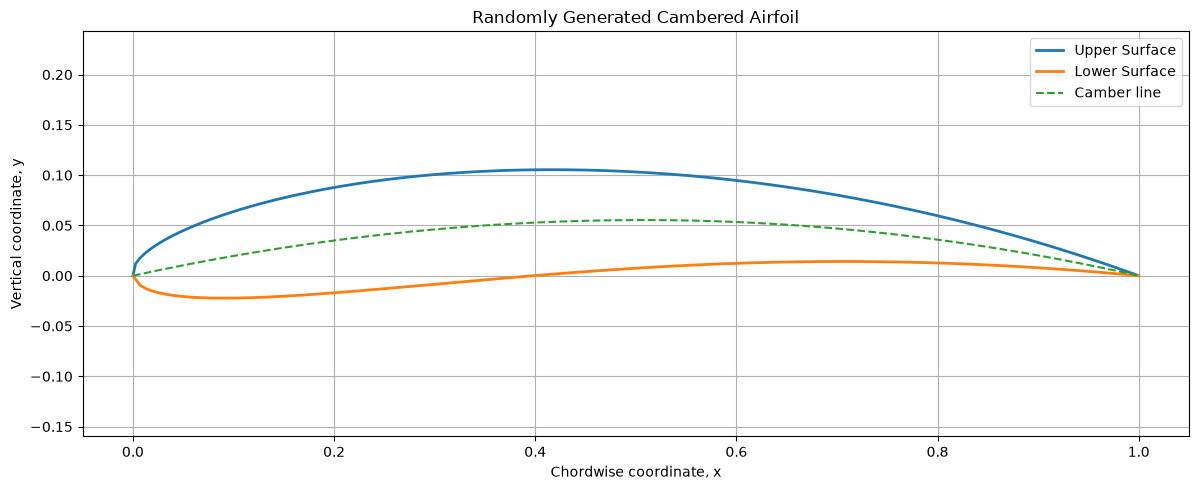

In [7]:
plt.figure(figsize=(12,5))

plt.plot(xu,yu, label= "Upper Surface", linewidth =2)
plt.plot(xl,yl, label="Lower Surface", linewidth =2)
plt.plot(x,yc*c, "--", label="Camber line")

plt.xlabel("Chordwise coordinate, x")
plt.ylabel("Vertical coordinate, y")
plt.title("Randomly Generated Cambered Airfoil")

plt.axis("equal")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

## Implementing the Lagrange Interpolation

## Firstly the Lagrange function is defined

In [ ]:
def Lagrng(x, y, n, xx):
    total = np.zeros_like(np.asarray(xx, dtype=float))

    for i in range(n):
        product = y[i]

        for j in range(n):
            if i != j:
                product = product * (
                    (xx - x[j]) / (x[i] - x[j])
                )

        total = total + product

    return total

## In the next step we have given the input as the number of points that the Lagrange interpolation will use with respect to the orginal airfoil points. Thus creating the upper and lower surfaces.

In [ ]:
n = 12

indices = np.linspace(0, N - 1, n, dtype=int)
yld = yl[indices]

xud = xu[indices]
yud = yu[indices]

xld = xl[indices]

xx = np.linspace(0, 1, 400)

yu_lagrange = Lagrng(xud, yud, n, xx)
yl_lagrange = Lagrng(xld, yld, n, xx)

poly_upper = scipy_lagrange(xud, yud)
poly_lower = scipy_lagrange(xld, yld)

yu_scipy = poly_upper(xx)
yl_scipy = poly_lower(xx)



## Verificaton with the already existing function in Scipy

In [ ]:
print("\nVerification against SciPy:")
print("Upper surface maximum difference:",
      np.max(np.abs(yu_lagrange - yu_scipy)))
print("Lower surface maximum difference:",
      np.max(np.abs(yl_lagrange - yl_scipy)))

## Calculating the error by comparing with original airfoil

In [ ]:
#Calculating error for Lagrange interpolation
yu_true = np.interp(xx, xu, yu)
yl_true = np.interp(xx, xl, yl)

upper_error = yu_true - yu_lagrange
lower_error = yl_true - yl_lagrange

max_error = max(
    np.max(np.abs(upper_error)),
    np.max(np.abs(lower_error))
)

rms_error = np.sqrt(
    np.mean(np.concatenate([
        upper_error**2,
        lower_error**2
    ]))
)

print("\nReconstruction errors:")
print(f"Maximum absolute error: {max_error:.8e}")
print(f"RMS error: {rms_error:.8e}")

## Now plotting the actual graph for Lagrange interpolation along with the dashed line denoting the original airfoil

In [ ]:
plt.figure(figsize=(12, 6))

plt.plot(xu, yu, label="Original upper surface")
plt.plot(xl, yl, label="Original lower surface")

plt.plot(xx, yu_lagrange, "--",
         label="Lagrange upper surface")
plt.plot(xx, yl_lagrange, "--",
         label="Lagrange lower surface")

plt.scatter(xud, yud, s=25, label="Upper data points")
plt.scatter(xld, yld, s=25, label="Lower data points")

plt.xlabel("x/c")
plt.ylabel("y/c")
plt.title("Airfoil Reconstruction Using Lagrange Interpolation")
plt.axis("equal")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

# Cubic Spline Interpolation

## Defining the Cubic Spline Interpolation function

### Define the cubic spline function and validate the input data

In [ ]:
def cubic_spline(x_data, y_data, xx):
    x_data = np.asarray(x_data, dtype=float)
    y_data = np.asarray(y_data, dtype=float)
    xx = np.asarray(xx, dtype=float)

    n_points = len(x_data)
    if n_points < 2:
        raise ValueError("At least two data points are required.")
    if len(y_data) != n_points:
        raise ValueError("x_data and y_data must have equal lengths.")
    if np.any(np.diff(x_data) <= 0):
        raise ValueError("x_data must be strictly increasing.")

### Constructing and solvinng the system of equations

In [ ]:
h = np.diff(x_data)
A = np.zeros((n_points, n_points))
rhs = np.zeros(n_points)

A[0, 0] = 1.0
A[-1, -1] = 1.0

for i in range(1, n_points - 1):
    A[i, i-1] = h[i-1]
    A[i, i] = 2.0 * (h[i-1] + h[i])
    A[i, i+1] = h[i]
    rhs[i] = 6.0 * (
        (y_data[i+1] - y_data[i]) / h[i]
        - (y_data[i] - y_data[i-1]) / h[i-1]
    )

M = np.linalg.solve(A, rhs)

### Evaluating the spline at the required coordinates

In [ ]:
interval = np.searchsorted(x_data, xx, side="right") - 1
interval = np.clip(interval, 0, n_points - 2)

left = x_data[interval]
right = x_data[interval + 1]
hi = right - left

term1 = M[interval] * (right - xx)**3 / (6.0 * hi)
term2 = M[interval + 1] * (xx - left)**3 / (6.0 * hi)
term3 = (
    y_data[interval] - M[interval] * hi**2 / 6.0
) * (right - xx) / hi
term4 = (
    y_data[interval + 1] - M[interval + 1] * hi**2 / 6.0
) * (xx - left) / hi

return term1 + term2 + term3 + term4

### Selecting points, transforming the coordinate, and reconstructing the airfoil

In [ ]:
indices = np.linspace(0, N - 1, n, dtype=int)

u = np.sqrt(x / c)
u_data = u[indices]

xx = np.linspace(0.0, c, 1000)
uu = np.sqrt(xx / c)

xu_data = xu[indices]
yu_data = yu[indices]
xl_data = xl[indices]
yl_data = yl[indices]

xu_spl = cubic_spline(u_data, xu_data, uu)
yu_spl = cubic_spline(u_data, yu_data, uu)
xl_spl = cubic_spline(u_data, xl_data, uu)
yl_spl = cubic_spline(u_data, yl_data, uu)

### Now calculating the errors and reconstructing the airfoil

In [ ]:
yu_true_spline = np.interp(xx, xu, yu)
yl_true_spline = np.interp(xx, xl, yl)

upper_error_spline = yu_true_spline - yu_spl
lower_error_spline = yl_true_spline - yl_spl

max_error_spline = max(
    np.max(np.abs(upper_error_spline)),
    np.max(np.abs(lower_error_spline))
)

rms_error_spline = np.sqrt(
    np.mean(np.concatenate([
        upper_error_spline**2,
        lower_error_spline**2
    ]))
)

### Now plotting the Cubic Spline interpolation graph

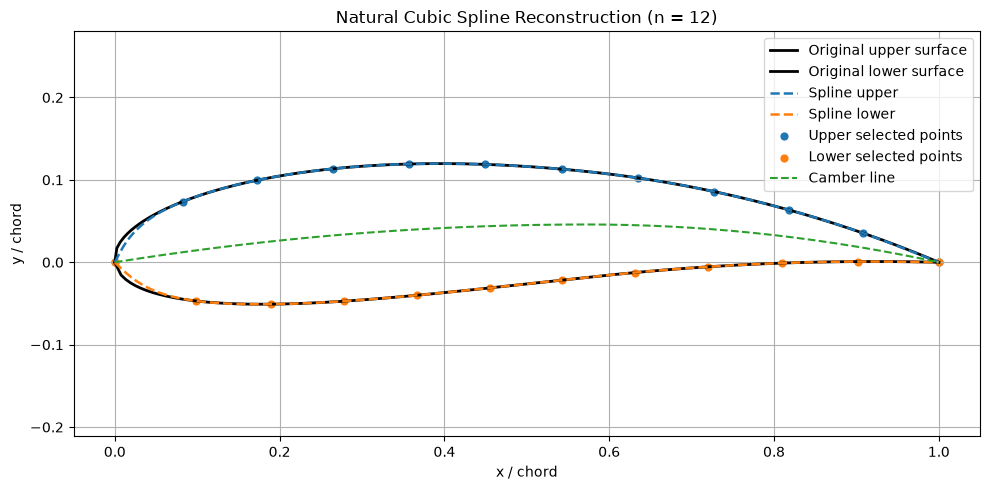

In [10]:
plt.figure(figsize=(10, 5))
plt.plot(xu, yu, "k-", linewidth=2, label="Original upper surface")
plt.plot(xl, yl, "k-", linewidth=2, label="Original lower surface")
plt.plot(xu_spl, yu_spl, "--", linewidth=1.8, label="Spline upper")
plt.plot(xl_spl, yl_spl, "--", linewidth=1.8, label="Spline lower")
plt.scatter(xu_data, yu_data, s=24, label="Upper selected points")
plt.scatter(xl_data, yl_data, s=24, label="Lower selected points")
plt.xlabel("x / chord")
plt.ylabel("y / chord")
plt.plot(x, yc*c, "--", label="Camber line")
plt.title(f"Natural Cubic Spline Reconstruction (n = {n})")
plt.axis("equal")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

 # Results and Discussion

## 1. Results
→ A cambered airfoil was generated using random parameters \(m=0.04644\), \(p=0.37555\), and \(t=0.16303\).

→ The original airfoil geometry contained 200 points with chord length \(c=1\).

→ Twelve points were selected to reconstruct the airfoil using Lagrange interpolation.

→ Natural cubic spline interpolation was performed using the transformed chordwise parameter \\(u=\sqrt{x/c}\\).

→ Maximum absolute error and RMS error were calculated for both surfaces.

## 2. Error Comparison (with one of the inputs as m=0.04644, p=0.37555 and t=0.16303)

| Method | Surface | Maximum error | RMS error |
|---|---|---:|---:|
| Lagrange | Upper | 0.016863 | 0.002555 |
| Lagrange | Lower | 0.004378 | 0.000746 |
| Cubic spline | Upper | 0.014135 | 0.001476 |
| Cubic spline | Lower | 0.007952 | 0.001163 |

## 3. Discussion
→ Lagrange interpolation constructs a single polynomial passing through the selected points.

→ Cubic spline interpolation uses piecewise cubic polynomials joined smoothly.

→ The spline produced lower errors for the upper surface in this test.

→ Lagrange interpolation produced lower errors for the lower surface.

→ Therefore, neither method was uniformly more accurate for both surfaces.

→ Point distribution significantly affects reconstruction accuracy.

→ The leading edge requires particular attention because of its high curvature.

→ Maximum error indicates the largest local deviation from the reference surface.

→ RMS error represents the overall magnitude of reconstruction error.

## 4. Conclusion
→ Both methods reconstructed the airfoil using fewer points than the original geometry.

→ The cubic spline performed better on the upper surface according to both error metrics.

→ Lagrange interpolation performed better on the lower surface according to both metrics.

→ The results apply to this particular randomly generated airfoil.

→ Different parameters and point distributions may produce different errors.

→ These values were calculated using a numerical implementation of the described methods, not by executing your exact original script.

## Summary

→ A cambered airfoil was generated using randomly selected parameters \(m\), \(p\), and \(t\), with 200 points defining the original geometry.

→ The airfoil was reconstructed using Lagrange interpolation and natural cubic spline interpolation, using 12 selected points.

→ The transformed chordwise parameter \(u=\sqrt{x/c}\) was used for spline interpolation.

→ Maximum absolute error and RMS error were calculated to compare the accuracy of both methods.


# Improvement of Airfoil Reconstruction Using Cosine Spacing

## 1. Introduction

Cosine spacing is a technique used to distribute points non-uniformly along an airfoil chord. Unlike uniform spacing, where points are equally separated, cosine spacing places more points near the leading edge and trailing edge. This helps represent regions where the airfoil geometry changes rapidly, particularly near the leading edge.

## 2. Mathematical Formulation

The chordwise coordinates for cosine spacing are calculated using the following formula:

$$
x_i = \frac{c}{2}\left[1-\cos\left(\frac{i\pi}{N-1}\right)\right]
$$

where:

- `x_i` is the chordwise coordinate of the `i`-th point.
- `c` is the chord length.
- `N` is the total number of points.
- `i` is the point index, ranging from `0` to `N-1`.

For a unit chord, `c = 1`, the coordinates vary from `x = 0` at the leading edge to `x = 1` at the trailing edge.

## 3. Implementation in Python

Uniform spacing can be generated using:

```python
x = np.linspace(0, c, N)
```

To use cosine spacing, replace it with:

```python
beta = np.linspace(0, np.pi, N)
x = 0.5 * c * (1 - np.cos(beta))
```

Here, `beta` is an angular parameter used to generate the chordwise coordinates. The cosine function makes the point spacing smaller near both ends of the chord and larger near the middle.

## 4. Advantages of Cosine Spacing

→ **Improved leading-edge representation:** More points are placed near the leading edge, where curvature changes rapidly.

→ **Improved trailing-edge representation:** The increased point density helps represent the geometry near the trailing edge.

→ **Potentially better interpolation:** A suitable point distribution can reduce reconstruction errors for both Lagrange interpolation and cubic spline interpolation.

→ **Efficient use of points:** More points are allocated to regions requiring greater geometric detail instead of distributing all points uniformly.

## 5. Comparison of Uniform and Cosine Spacing

Uniform spacing distributes points at equal intervals along the chord, whereas cosine spacing concentrates points near the leading and trailing edges. With a limited number of interpolation points, cosine spacing may represent the airfoil geometry more accurately in these regions.

However, the improvement depends on the airfoil geometry, interpolation method, and number of points used. Cosine spacing does not guarantee lower errors in every case.

## 6. Method to Evaluate the Improvement

The effectiveness of cosine spacing can be evaluated by running the reconstruction code twice using the same airfoil parameters and number of points.

→ First, reconstruct the airfoil using uniformly spaced points.

→ Next, reconstruct the same airfoil using cosine-spaced points.

→ Plot both reconstructed airfoils against the original geometry.

→ Compare the maximum absolute error and RMS error for both cases.

For a fair comparison, the same airfoil parameters and error-evaluation procedure must be maintained in both cases.

## 7. Conclusion

Cosine spacing provides a non-uniform distribution of points that concentrates data near the leading and trailing edges of an airfoil. This can improve the representation of regions with rapid geometric variation and potentially enhance interpolation accuracy. Its effectiveness should be verified by comparing the reconstruction errors obtained using uniform and cosine spacing.
